# 04 – X-ray analysis

Analysis of the planar X-ray image of the phantoms, with focus on phantom A3.

The notebook follows the same structure as the CT and MRI notebooks:

| Section | Content | Guide |
|---|---|---|
| 0 | Setup, data and acquisition parameters | – |
| 1 | Locating phantom A3 in the projection | – |
| 2 | Number, geometry and arrangement of objects | 1.1 |
| 3 | Internal structure and material characteristics | 1.2 |
| 4 | Contrast and image quality | 1.3 |
| 5 | Summary for the multimodal comparison | 1.4–1.5 |
| 6 | Reproducibility record | – |

Each analysis follows **question $\rightarrow$ method $\rightarrow$ result $\rightarrow$ interpretation/limitations**. Coordinates for ROIs and measurement lines are chosen by the group and written in the cells marked *Placeholder*.

---
---
## 0. Setup and data

In [1]:
# === Autoreload: pick up changes in src/ automatically ===
%load_ext autoreload
%autoreload 2

# === Imports ===
import sys
sys.path.append("..")

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
import pydicom

# === Our own functions ===
from src.data_io import load_image, save_table, save_figure
from src.viewers import show_slice

# === Paths ===
RAW       = Path("../data/raw")
PROCESSED = Path("../data/processed")
RESULTS   = Path("../results")

XRAY_DIR  = RAW / "XRay"
XRAY_FILE = sorted(XRAY_DIR.glob("*.dcm"))[0]      # The folder contains one image

### What the X-ray image shows

A planar X-ray image is a **projection**: each pixel shows how much the beam was attenuated along its whole path through the phantom. For a beam passing through materials with linear attenuation coefficients $\mu$, the transmitted intensity is

$$I = I_0 \cdot e^{-\int \mu \, ds}$$

so a pixel depends on the **sum** of attenuation along the path, not on any single structure. Objects lying behind each other along the beam overlap in the image, and depth information is lost.

Two consequences for the analysis:

- **Intensities are not calibrated.** Unlike CT, the pixel values depend on kVp, mAs, the detector and image processing, so they can only be compared within the image.
- **Magnification.** The beam diverges from the source, so objects are projected larger than they are. The magnification factor is

$$m = \frac{S_I}{S_O}$$

where $S_I$ is the source-to-detector distance and $S_O$ the source-to-object distance. Sizes measured in the image must be divided by $m$, unless the pixel spacing is already corrected for it.

### Load the X-ray image

The image is loaded as a 2D array. If the image is stored as `MONOCHROME1` (high values shown dark), it is inverted, so that high attenuation is shown bright, as in CT.

In [2]:
xray, xray_spacing = load_image(XRAY_FILE)                  # Load the X-ray image and pixel spacing (mm)
hx = pydicom.dcmread(XRAY_FILE, stop_before_pixels=True)    # X-ray header without pixel data

print(f"File: {XRAY_FILE.name}")
print(f"Shape (rows, cols): {xray.shape}")
print(f"Pixel spacing used (mm): {tuple(round(s, 4) for s in xray_spacing)}")
print(f"Value range: {xray.min():.0f} to {xray.max():.0f}")
print(f"Photometric interpretation: {hx.get('PhotometricInterpretation')}")

File: X-ray_3A.dcm
Shape (rows, cols): (3032, 2520)
Pixel spacing used (mm): (0.139, 0.139)
Value range: 0 to 4080
Photometric interpretation: MONOCHROME2


### Acquisition parameters

The exposure and geometry parameters are collected for the Materials and methods section. Two pixel spacings may be stored:

- `ImagerPixelSpacing`: the pixel size **at the detector**.
- `PixelSpacing`: the pixel size, possibly **corrected for magnification** (calibrated to the object plane).

If they differ, their ratio is the magnification correction applied by the system. The distances give the magnification $m = S_I / S_O$.

In [ ]:
xray_params = pd.Series({
    "Manufacturer":                       hx.get("Manufacturer"),
    "Model":                              hx.get("ManufacturerModelName"),
    "Modality":                           hx.get("Modality"),
    "View position":                      hx.get("ViewPosition"),
    "Tube voltage (kVp)":                 hx.get("KVP"),
    "Tube current (mA)":                  hx.get("XRayTubeCurrent"),
    "Exposure time (ms)":                 hx.get("ExposureTime"),
    "Exposure (mAs)":                     hx.get("Exposure"),
    "Source-detector distance S_I (mm)":  hx.get("DistanceSourceToDetector"),
    "Source-object distance S_O (mm)":    hx.get("DistanceSourceToPatient"),
    "Magnification factor (header)":      hx.get("EstimatedRadiographicMagnificationFactor"),
    "PixelSpacing (mm)":                  hx.get("PixelSpacing"),
    "ImagerPixelSpacing (mm)":            hx.get("ImagerPixelSpacing"),
    "Matrix (rows x cols)":               f"{hx.get('Rows')} x {hx.get('Columns')}",
    "Bits stored":                        hx.get("BitsStored"),
    "Photometric interpretation":         hx.get("PhotometricInterpretation"),
    "Presentation intent":                hx.get("PresentationIntentType"),
    }, name="X-ray")

# Magnification from the distances, if both are stored
S_I, S_O = hx.get("DistanceSourceToDetector"), hx.get("DistanceSourceToPatient")
if S_I and S_O:
    xray_params["Magnification m = S_I / S_O"] = round(float(S_I) / float(S_O), 3)

display(xray_params.to_frame())

,X-ray
Manufacturer,Carestream
Model,DRX-Evolution
Modality,DX
View position,PA
Tube voltage (kVp),40.0
Tube current (mA),125
Exposure time (ms),8
Exposure (mAs),1
Source-detector distance S_I (mm),0.0
Source-object distance S_O (mm),None


> **Notes on the parameters:**
> - ...
> - ...

### Overview of the full image

The whole image with axes in mm (at the detector, using the pixel spacing above). A planar image needs no slice viewer, so a static figure is used. It also works in HTML exports and on GitHub.

Saved figure: images/xray_full.png


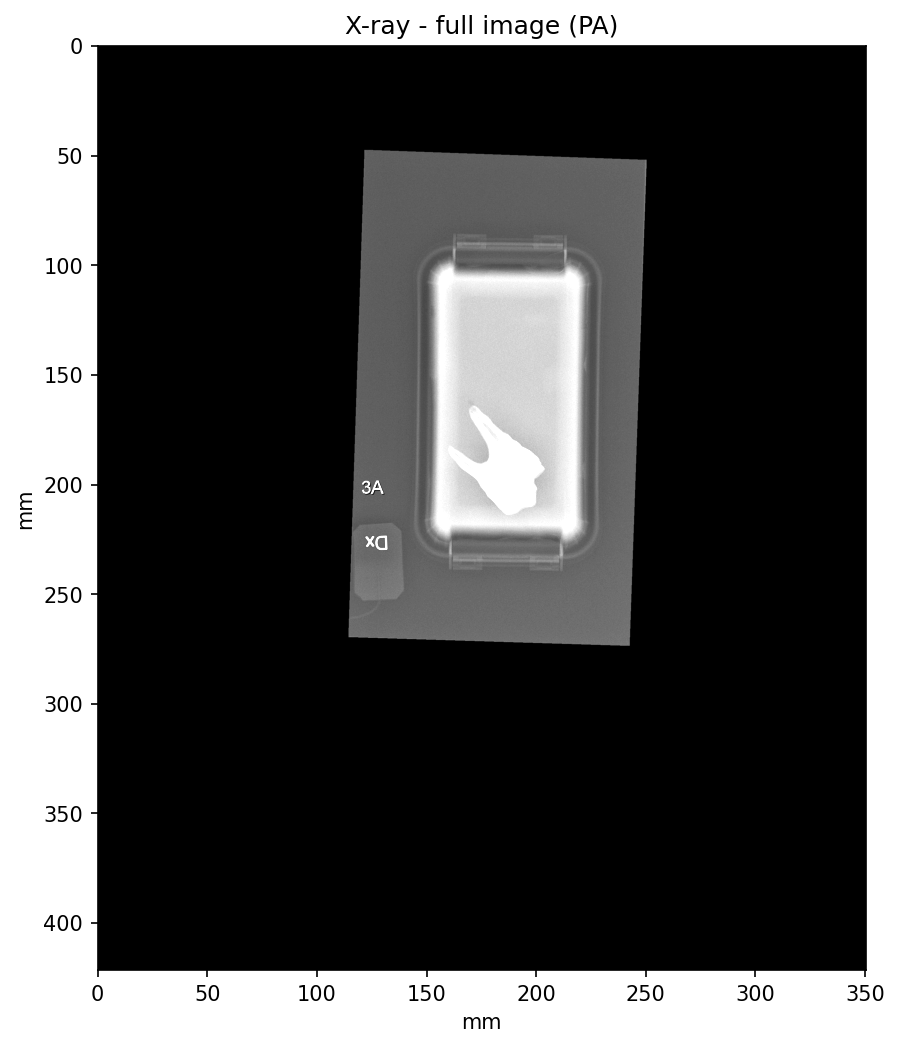

In [9]:
lo, hi = np.percentile(xray, [1, 99])                  # Display window: ignore extreme pixels

fig, ax = plt.subplots(figsize=(7, 8), dpi=150)
show_slice(ax, xray, xray_spacing, vmin=lo, vmax=hi)
ax.set_title(f"X-ray - full image ({hx.get('ViewPosition', '')})")
save_figure(fig, "xray_full")
plt.show()

---
---
## **1. Locating phantom A3**
